# 02.1 EDA y limpieza

Entrada: `data/interim/dev.csv`. Salida: `data/processed/austin_animal_center_clean.csv`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA = Path("..") / "data"
df = pd.read_csv(DATA / "interim" / "dev.csv")
print(df.shape)
df.head()

(63717, 41)


,age_upon_outcome,animal_id_outcome,date_of_birth,outcome_subtype,outcome_type,sex_upon_outcome,age_upon_outcome_(days),age_upon_outcome_(years),age_upon_outcome_age_group,outcome_datetime,outcome_month,outcome_year,outcome_monthyear,outcome_weekday,outcome_hour,outcome_number,dob_year,dob_month,dob_monthyear,age_upon_intake,animal_id_intake,animal_type,breed,color,found_location,intake_condition,intake_type,sex_upon_intake,count,age_upon_intake_(days),age_upon_intake_(years),age_upon_intake_age_group,intake_datetime,intake_month,intake_year,intake_monthyear,intake_weekday,intake_hour,intake_number,time_in_shelter,time_in_shelter_days
0,10 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,3650,10.0,"(7.5, 10.0]",2017-12-07 14:07:00,12,2017,2017-12,Thursday,0,1.0,2007,7,2017-12,10 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,Colony Creek And Hunters Trace in Austin (TX),Normal,Stray,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2017-12-07 00:00:00,12,2017,2017-12,Thursday,14,1.0,0 days 14:07:00.000000000,0.588194
1,7 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2555,7.0,"(5.0, 7.5]",2014-12-20 16:35:00,12,2014,2014-12,Saturday,16,2.0,2007,7,2014-12,7 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research Blvd in Austin (TX),Normal,Public Assist,Neutered Male,1,2555,7.0,"(5.0, 7.5]",2014-12-19 10:21:00,12,2014,2014-12,Friday,10,2.0,1 days 06:14:00.000000000,1.259722
2,6 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2190,6.0,"(5.0, 7.5]",2014-03-08 17:10:00,3,2014,2014-03,Saturday,17,3.0,2007,7,2014-03,6 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research in Austin (TX),Normal,Public Assist,Neutered Male,1,2190,6.0,"(5.0, 7.5]",2014-03-07 14:26:00,3,2014,2014-03,Friday,14,3.0,1 days 02:44:00.000000000,1.113889
3,10 years,A047759,2004-04-02 00:00:00,Partner,Transfer,Neutered Male,3650,10.0,"(7.5, 10.0]",2014-04-07 15:12:00,4,2014,2014-04,Monday,15,1.0,2004,4,2014-04,10 years,A047759,Dog,Dachshund,Tricolor,Austin (TX),Normal,Owner Surrender,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2014-04-02 15:55:00,4,2014,2014-04,Wednesday,15,1.0,4 days 23:17:00.000000000,4.970139
4,16 years,A134067,1997-10-16 00:00:00,NaN,Return to Owner,Neutered Male,5840,16.0,"(15.0, 17.5]",2013-11-16 11:54:00,11,2013,2013-11,Saturday,11,1.0,1997,10,2013-11,16 years,A134067,Dog,Shetland Sheepdog,Brown/White,12034 Research Blvd in Austin (TX),Injured,Public Assist,Neutered Male,1,5840,16.0,"(15.0, 17.5]",2013-11-16 09:02:00,11,2013,2013-11,Saturday,9,1.0,0 days 02:52:00.000000000,0.119444


## 1. Limpieza inicial

In [2]:
n0 = len(df)
print("Duplicados:", df.duplicated().sum())
print("outcome_type nulo:", df["outcome_type"].isna().sum())

df = df.drop_duplicates().dropna(subset=["outcome_type"]).reset_index(drop=True)

# Fechas a datetime y columna de texto redundante
date_cols = ["intake_datetime", "outcome_datetime", "date_of_birth"]
df[date_cols] = df[date_cols].apply(pd.to_datetime, errors="coerce")
df = df.drop(columns=["time_in_shelter"])

print("Fechas no válidas:", df[date_cols].isna().sum().sum())
print("Estancias negativas:", (df["time_in_shelter_days"] < 0).sum())
df = df[df["time_in_shelter_days"] >= 0].reset_index(drop=True)

print(f"{n0} -> {len(df)} filas, {df.shape[1]} columnas")

Duplicados: 28
outcome_type nulo: 8
Fechas no válidas: 0
Estancias negativas: 0
63717 -> 63681 filas, 40 columnas


- Se eliminan 28 duplicados y 8 filas sin `outcome_type`.
- Las fechas se convierten sin errores y no hay estancias negativas.

## 2. Variables objetivo

In [3]:
adopted = df[df["outcome_type"].isin(["Adoption", "Rto-Adopt"])]
p95 = adopted["time_in_shelter_days"].quantile(0.95)
order = df["outcome_type"].value_counts().index

pd.DataFrame({
    "n": df["outcome_type"].value_counts(),
    "%": (df["outcome_type"].value_counts(normalize=True) * 100).round(2),
})

,n,%
outcome_type,,
Adoption,26935,42.30
Transfer,19031,29.88
Return to Owner,11757,18.46
Euthanasia,4986,7.83
Died,547,0.86
Disposal,245,0.38
Rto-Adopt,138,0.22
Missing,32,0.05
Relocate,10,0.02


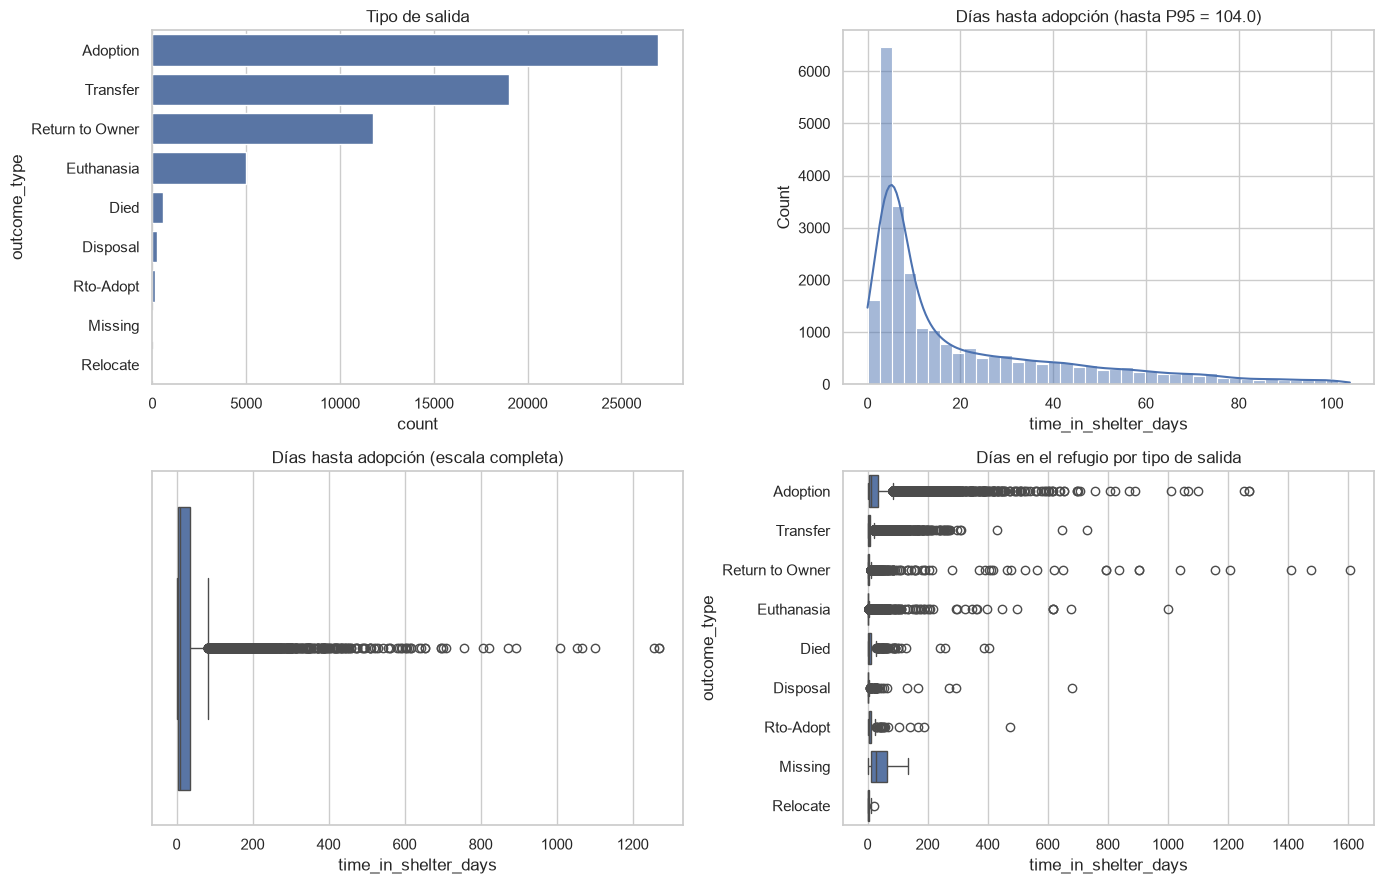

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df, y="outcome_type", order=order, ax=axes[0, 0])
axes[0, 0].set_title("Tipo de salida")

sns.histplot(adopted.loc[adopted["time_in_shelter_days"] <= p95, "time_in_shelter_days"],
             bins=40, kde=True, ax=axes[0, 1])
axes[0, 1].set_title(f"Días hasta adopción (hasta P95 = {p95:.1f})")

sns.boxplot(x=adopted["time_in_shelter_days"], ax=axes[1, 0])
axes[1, 0].set_title("Días hasta adopción (escala completa)")

sns.boxplot(data=df, x="time_in_shelter_days", y="outcome_type", order=order, ax=axes[1, 1])
axes[1, 1].set_title("Días en el refugio por tipo de salida")

plt.tight_layout()
plt.show()

In [5]:
def summary(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series({"count": s.count(), "mean": s.mean(), "std": s.std(), "min": s.min(),
                      "q1": q1, "median": s.median(), "q3": q3, "iqr": q3 - q1,
                      "p95": s.quantile(0.95), "max": s.max()})

print("Adoptados (Adoption + Rto-Adopt)")
print(summary(adopted["time_in_shelter_days"]).round(2))

df.groupby("outcome_type")["time_in_shelter_days"].agg(
    count="count", mean="mean", std="std",
    q1=lambda x: x.quantile(0.25), median="median", q3=lambda x: x.quantile(0.75),
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25), max="max",
).sort_values("count", ascending=False).round(2)

Adoptados (Adoption + Rto-Adopt)
count     27073.00
mean         29.45
std          52.31
min           0.00
q1            4.96
median       10.25
q3           36.26
iqr          31.29
p95         103.98
max        1268.97
dtype: float64


,count,mean,std,q1,median,q3,iqr,max
outcome_type,,,,,,,,
Adoption,26935,29.50,52.32,4.96,10.28,36.36,31.39,1268.97
Transfer,19031,9.26,20.76,0.80,3.99,8.89,8.09,729.95
Return to Owner,11757,5.27,38.63,0.57,1.84,4.95,4.38,1606.19
Euthanasia,4986,5.17,30.84,0.02,0.23,1.59,1.56,999.26
Died,547,13.04,32.90,0.68,3.83,11.80,11.12,405.15
Disposal,245,11.19,52.42,0.24,0.58,2.75,2.50,681.12
Rto-Adopt,138,18.92,47.78,4.80,6.12,13.08,8.29,476.02
Missing,32,44.14,41.27,12.86,29.48,63.82,50.96,133.57
Relocate,10,4.35,6.95,0.71,0.98,4.95,4.24,21.93


- Tres salidas suman el 90,6 %: `Adoption` (42,3 %), `Transfer` (29,9 %) y `Return to Owner` (18,5 %).
- Adopciones (`Adoption` + `Rto-Adopt`): 27 073 animales.
- Los días hasta adopción tienen cola larga: mediana 10,25 y media 29,45. Para regresión conviene transformar el objetivo.
- Las demás salidas son más rápidas: eutanasia 0,2 días, retorno a dueño 1,8 y transferencia 4,0.

## 3. Variables de ingreso

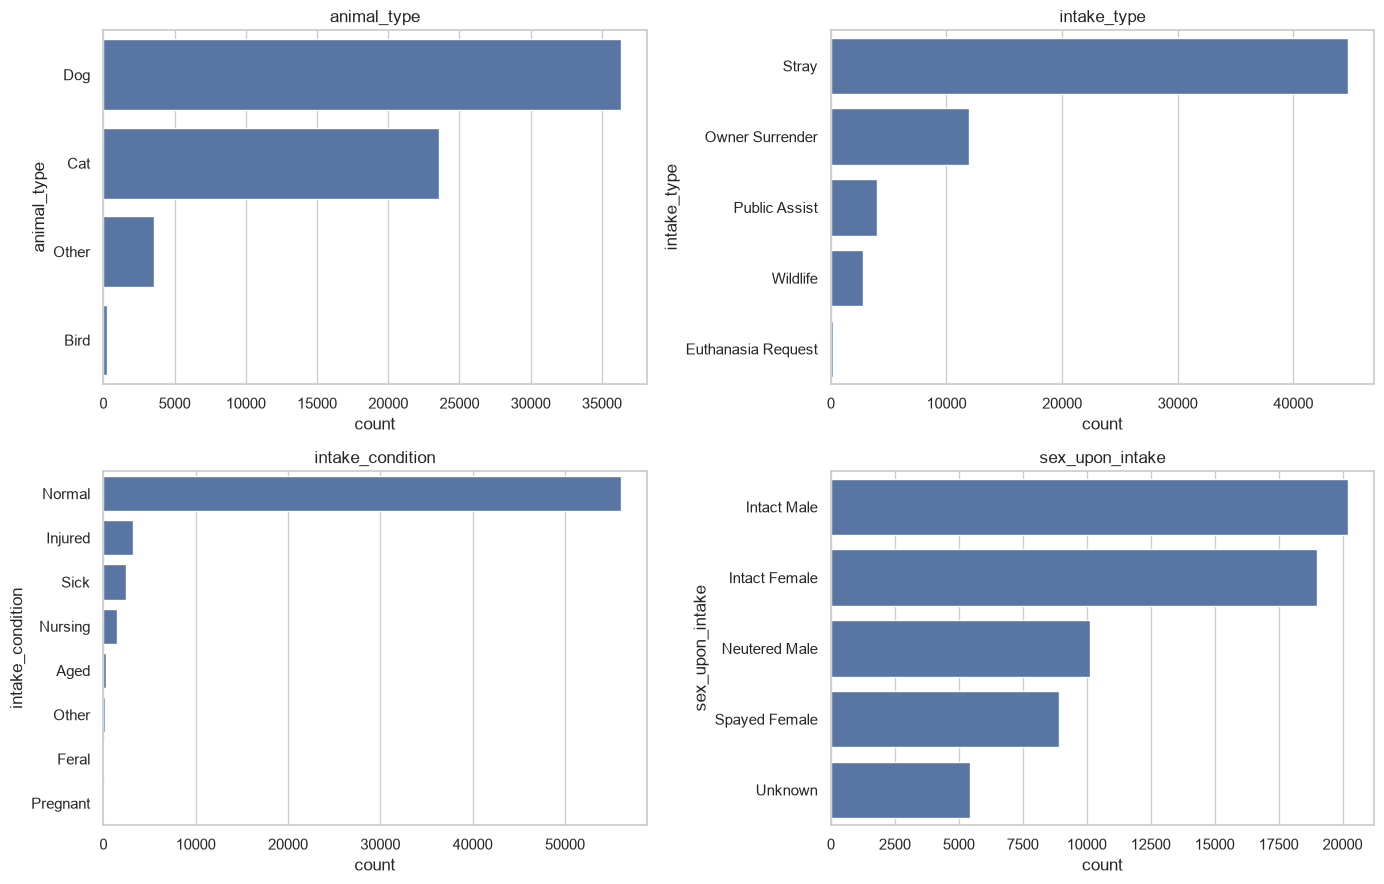

                 n      %
animal_type              
Dog          36316  57.03
Cat          23559  37.00
Other         3529   5.54
Bird           277   0.43 

                        n      %
intake_type                     
Stray               44744  70.26
Owner Surrender     11963  18.79
Public Assist        4015   6.30
Wildlife             2773   4.35
Euthanasia Request    186   0.29 

                      n      %
intake_condition              
Normal            56031  87.99
Injured            3227   5.07
Sick               2424   3.81
Nursing            1521   2.39
Aged                250   0.39
Other               126   0.20
Feral                70   0.11
Pregnant             32   0.05 

                     n      %
sex_upon_intake              
Intact Male      20220  31.75
Intact Female    18986  29.81
Neutered Male    10126  15.90
Spayed Female     8921  14.01
Unknown           5427   8.52
NaN                  1   0.00 

breed -> 1946 valores distintos
breed
Domestic Shorthai

In [6]:
cols = ["animal_type", "intake_type", "intake_condition", "sex_upon_intake"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, cols):
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in cols:
    print(pd.DataFrame({
        "n": df[col].value_counts(dropna=False),
        "%": (df[col].value_counts(normalize=True, dropna=False) * 100).round(2),
    }), "\n")

for col in ["breed", "color", "age_upon_intake"]:
    print(col, "->", df[col].nunique(), "valores distintos")
    print(df[col].value_counts().head(5).to_string(), "\n")

- Perros 57,0 % y gatos 37,0 %.
- 70,3 % entra como `Stray`.
- 88,0 % entra en condición `Normal`.
- Más del 60 % entra sin esterilizar. `Unknown` es 8,5 % y hay 1 nulo.
- `breed` (1 946), `color` (488) y `age_upon_intake` (46) tienen muchas categorías: habrá que agruparlas.

## 4. Relación con el objetivo

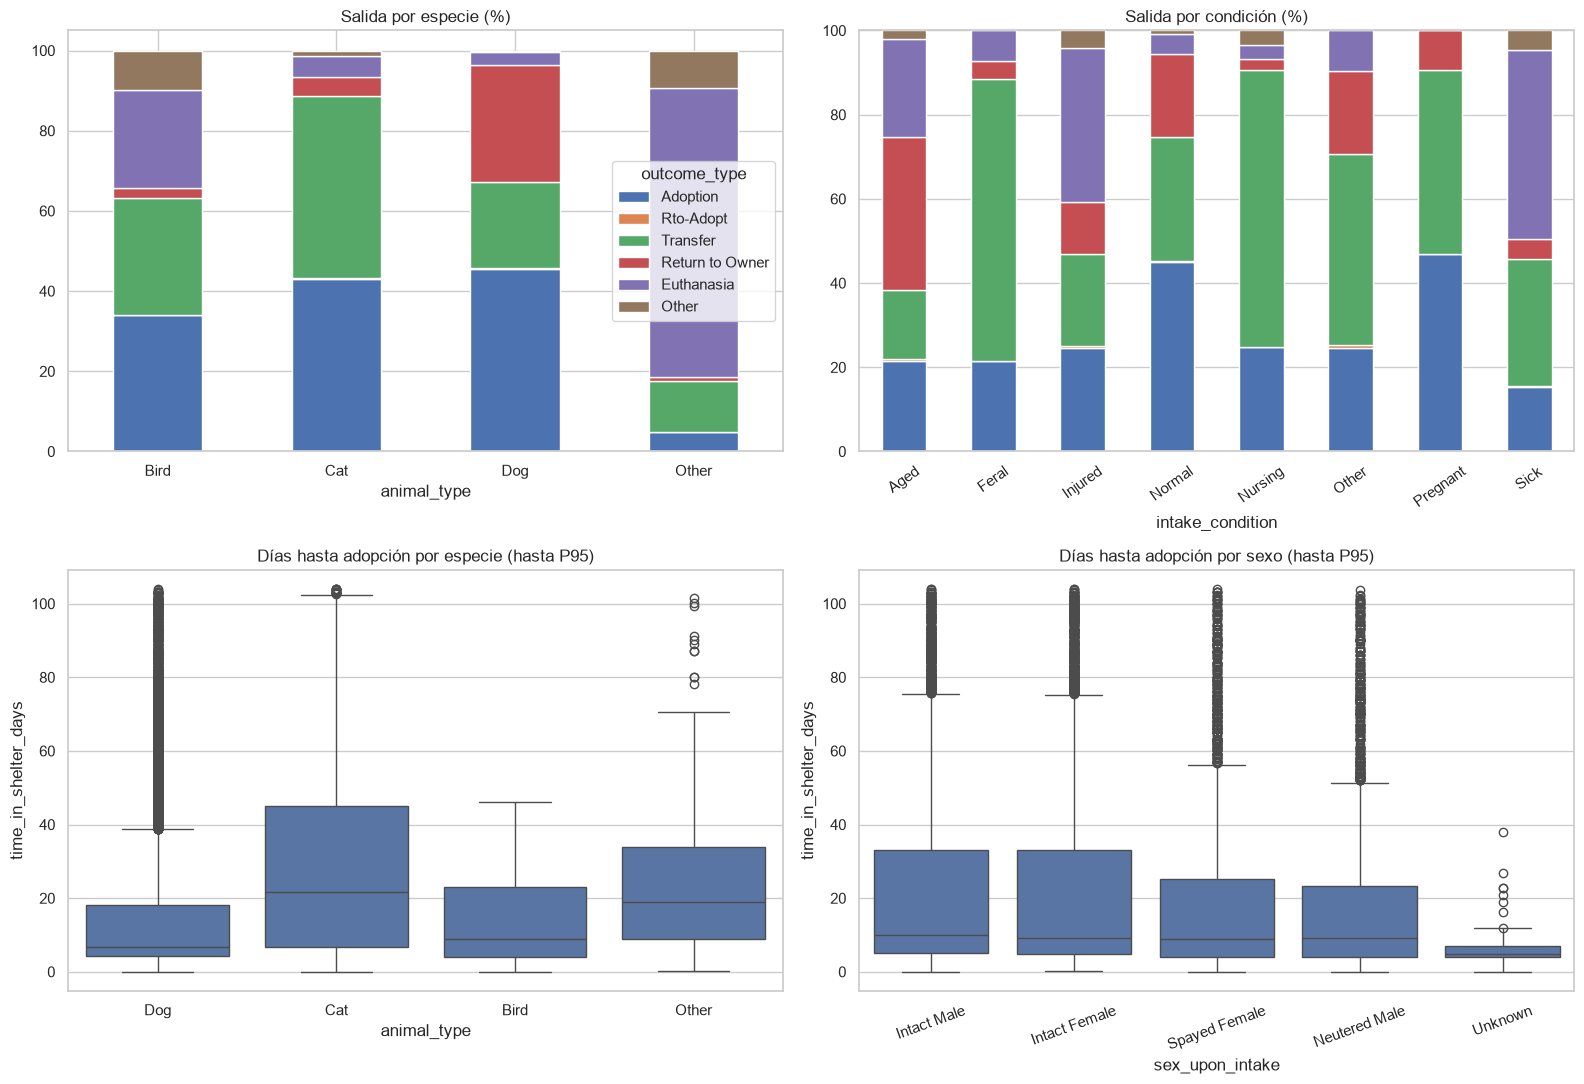

outcome_type,Adoption,Rto-Adopt,Transfer,Return to Owner,Euthanasia,Other
animal_type,,,,,,
Bird,33.94,0.00,29.24,2.53,24.55,9.75
Cat,43.07,0.13,45.44,4.84,5.06,1.46
Dog,45.50,0.29,21.46,29.13,3.23,0.38
Other,4.85,0.00,12.75,0.88,72.29,9.24


outcome_type,Adoption,Rto-Adopt,Transfer,Return to Owner,Euthanasia,Other
intake_condition,,,,,,
Aged,21.60,0.40,16.40,36.40,23.20,2.00
Feral,21.43,0.00,67.14,4.29,7.14,0.00
Injured,24.60,0.37,21.85,12.52,36.50,4.15
Normal,45.11,0.22,29.32,19.77,4.63,0.95
Nursing,24.72,0.00,65.88,2.63,3.22,3.55
Other,24.60,0.79,45.24,19.84,9.52,0.00
Pregnant,46.88,0.00,43.75,9.38,0.00,0.00
Sick,15.35,0.12,30.28,4.70,44.97,4.58


In [7]:
top = ["Adoption", "Rto-Adopt", "Transfer", "Return to Owner", "Euthanasia"]
grouped = df["outcome_type"].where(df["outcome_type"].isin(top), "Other")
cols_order = top + ["Other"]

def pct(col):
    return (pd.crosstab(df[col], grouped, normalize="index") * 100).reindex(columns=cols_order, fill_value=0)

by_animal, by_cond = pct("animal_type"), pct("intake_condition")

adopted_zoom = adopted[adopted["time_in_shelter_days"] <= p95]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
by_animal.plot(kind="bar", stacked=True, ax=axes[0, 0], rot=0, title="Salida por especie (%)")
by_cond.plot(kind="bar", stacked=True, ax=axes[0, 1], rot=35, legend=False, title="Salida por condición (%)")
sns.boxplot(data=adopted_zoom, x="animal_type", y="time_in_shelter_days", ax=axes[1, 0])
axes[1, 0].set_title("Días hasta adopción por especie (hasta P95)")
sns.boxplot(data=adopted_zoom, x="sex_upon_intake", y="time_in_shelter_days",
            order=adopted_zoom["sex_upon_intake"].value_counts().index, ax=axes[1, 1])
axes[1, 1].set_title("Días hasta adopción por sexo (hasta P95)")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

display(by_animal.round(2))
display(by_cond.round(2))

In [8]:
def days_by(col):
    return adopted.groupby(col, dropna=False)["time_in_shelter_days"].agg(
        count="count", mean="mean",
        q1=lambda x: x.quantile(0.25), median="median", q3=lambda x: x.quantile(0.75),
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25), max="max",
    ).sort_values("count", ascending=False).round(2)

display(days_by("animal_type"))
display(days_by("sex_upon_intake"))

,count,mean,q1,median,q3,iqr,max
animal_type,,,,,,,
Dog,16631,24.67,4.26,7.10,22.18,17.92,1268.97
Cat,10177,37.40,7.11,24.29,50.22,43.12,1101.78
Other,171,30.00,9.10,20.10,36.55,27.45,235.04
Bird,94,12.70,4.15,8.96,22.91,18.76,46.07


,count,mean,q1,median,q3,iqr,max
sex_upon_intake,,,,,,,
Intact Male,9941,26.94,5.05,10.27,37.24,32.19,636.93
Intact Female,9760,28.27,4.99,10.12,37.96,32.97,1009.97
Spayed Female,3698,34.60,4.17,10.91,33.28,29.11,1268.97
Neutered Male,3618,34.58,4.26,10.96,31.11,26.85,1268.87
Unknown,56,7.31,3.94,4.90,7.09,3.15,37.85


- Perros: 45,5 % `Adoption` y 29,1 % vuelven con su dueño. Gatos: 43,1 % `Adoption` y 45,4 % transferidos.
- `Other` (fauna silvestre): 72,3 % eutanasia.
- `Sick` y `Injured` tienen más eutanasia (45,0 % y 36,5 %). `Nursing` y `Feral` van sobre todo a `Transfer`.
- Los perros se adoptan más rápido (mediana 7,1 días) que los gatos (24,3).
- El sexo y el estado reproductivo casi no cambian la mediana (entre 10,1 y 11,0 días).

## 5. Limpieza final

Se conservan solo las columnas conocidas al ingreso, más los dos objetivos.

In [9]:
keep = ["animal_id_intake", "animal_type", "breed", "color", "sex_upon_intake",
        "age_upon_intake_(days)", "intake_type", "intake_condition", "intake_datetime",
        "intake_number", "found_location", "outcome_type", "time_in_shelter_days"]
print("Columnas descartadas:", df.shape[1] - len(keep))
clean = df[keep].copy()

# Texto: quitar espacios y completar nulos con "Unknown"
text_cols = [c for c in clean.select_dtypes(include=["object", "string"]).columns if c != "animal_id_intake"]
for col in text_cols:
    clean[col] = clean[col].str.strip()
    assert clean[col].nunique() == clean[col].str.lower().nunique(), f"{col}: mayúsculas inconsistentes"
    n = clean[col].isna().sum()
    if n:
        print(f"{col}: {n} nulos -> 'Unknown'")
        clean[col] = clean[col].fillna("Unknown")

# Valores imposibles y duplicados
clean = clean[(clean["time_in_shelter_days"] >= 0) & (clean["age_upon_intake_(days)"] >= 0)]
clean = clean.drop_duplicates().sort_values("intake_datetime").reset_index(drop=True)

out_dir = DATA / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
clean.to_csv(out_dir / "austin_animal_center_clean.csv", index=False)

print("Nulos restantes:", clean.isna().sum().sum())
print("Dimensiones:", clean.shape)

Columnas descartadas: 27
sex_upon_intake: 1 nulos -> 'Unknown'
Nulos restantes: 0
Dimensiones: (63681, 13)


- `sex_upon_intake` tenía 1 nulo, ahora `Unknown`.
- Resultado: 63 681 filas y 13 columnas, ordenadas por `intake_datetime`.

## 6. Verificación del archivo

In [10]:
check = pd.read_csv(out_dir / "austin_animal_center_clean.csv")
print(check.shape, "| nulos:", check.isna().sum().sum())
display(check.head())
display(check.tail())
display(check.describe().round(2))

(63681, 13) | nulos: 0


,animal_id_intake,animal_type,breed,color,sex_upon_intake,age_upon_intake_(days),intake_type,intake_condition,intake_datetime,intake_number,found_location,outcome_type,time_in_shelter_days
0,A521520,Dog,Border Terrier/Border Collie,White/Tan,Spayed Female,2555,Stray,Normal,2013-10-01 07:51:00,1.0,Norht Ec in Austin (TX),Return to Owner,0.325000
1,A664235,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.087500
2,A664236,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.090972
3,A664237,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.090972
4,A664233,Dog,Pit Bull Mix,Blue/White,Intact Female,1095,Stray,Injured,2013-10-01 08:53:00,1.0,7405 Springtime in Austin (TX),Euthanasia,0.277778


,animal_id_intake,animal_type,breed,color,sex_upon_intake,age_upon_intake_(days),intake_type,intake_condition,intake_datetime,intake_number,found_location,outcome_type,time_in_shelter_days
63676,A769064,Other,Bat Mix,Brown,Unknown,730,Wildlife,Normal,2018-03-29 17:13:00,1.0,2519 Scarbrough Dr in Travis (TX),Euthanasia,0.053472
63677,A769065,Other,Bat Mix,Brown,Unknown,365,Wildlife,Normal,2018-03-29 17:19:00,1.0,1122 Walton Ln in Austin (TX),Euthanasia,0.047917
63678,A767605,Dog,Boxer,Tan/White,Neutered Male,365,Owner Surrender,Normal,2018-03-29 18:15:00,1.0,Austin (TX),Adoption,2.013194
63679,A769066,Dog,Labrador Retriever Mix,Black/White,Intact Male,150,Stray,Normal,2018-03-29 18:19:00,1.0,12034 Research Blvd Sb in Austin (TX),Return to Owner,1.762500
63680,A769067,Dog,Boxer Mix,Brown Brindle,Spayed Female,3650,Stray,Aged,2018-03-29 18:20:00,1.0,11216 Jollyville Rd 216 in Austin (TX),Euthanasia,0.813889


,age_upon_intake_(days),intake_number,time_in_shelter_days
count,63681.00,63681.00,63681.00
mean,770.75,1.13,16.84
std,1059.20,0.46,42.23
min,0.00,1.00,0.00
25%,60.00,1.00,1.11
50%,365.00,1.00,5.00
75%,1095.00,1.00,13.84
max,9125.00,13.00,1606.19
